In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve


In [108]:
df = pd.read_csv('../data/kenya_synthetic_loans.csv')
print(df.shape)
print(df.columns.tolist())
display(pd.concat([df.head(), df.tail()]))

(5000, 18)
['loan_id', 'borrower_id', 'age', 'county', 'employment_type', 'monthly_income_kes', 'mpesa_avg_monthly_inflow_kes', 'mpesa_account_age_months', 'airtime_spend_monthly_kes', 'prior_loans', 'prior_defaults', 'active_loans_elsewhere', 'loan_amount_kes', 'term_days', 'fee_pct', 'channel', 'loan_to_income', 'defaulted_90dpd']


,loan_id,borrower_id,age,county,employment_type,monthly_income_kes,mpesa_avg_monthly_inflow_kes,mpesa_account_age_months,airtime_spend_monthly_kes,prior_loans,prior_defaults,active_loans_elsewhere,loan_amount_kes,term_days,fee_pct,channel,loan_to_income,defaulted_90dpd
0,L02765,B01921,41,Eldoret,Salaried,33300,22700,18,2300,0,0,0,15000,30,10.3,Mobile App,0.450,0
1,L04768,B03336,30,Mombasa,Salaried,116600,138700,57,3160,0,0,3,8100,21,6.8,Mobile App,0.069,0
2,L03815,B02652,44,Mombasa,Salaried,47300,64400,34,2890,0,0,0,18000,90,19.6,Mobile App,0.381,0
3,L03500,B02428,32,Machakos,Casual,16000,19600,49,680,0,0,1,5000,30,11.4,Mobile App,0.312,0
4,L02736,B01898,28,Nairobi,Self-employed,39600,50200,47,1830,0,0,1,10700,21,7.1,Mobile App,0.270,0
4995,L02896,B02007,22,Eldoret,Self-employed,42000,27200,8,1760,0,0,0,2600,60,14.4,Mobile App,0.062,0
4996,L02764,B01920,22,Nairobi,Self-employed,75600,75100,59,2120,0,0,2,14700,90,17.9,Bank digital,0.194,0
4997,L00906,B00629,18,Mombasa,Casual,8900,11900,41,480,2,1,3,4200,14,8.0,Mobile App,0.472,0
4998,L03981,B02773,31,Nakuru,Salaried,61900,48500,78,3460,0,0,1,9100,14,12.3,Mobile App,0.147,0
4999,L00236,B00167,35,Nairobi,Casual,17900,17700,46,780,0,0,4,13700,7,13.0,Mobile App,0.765,1


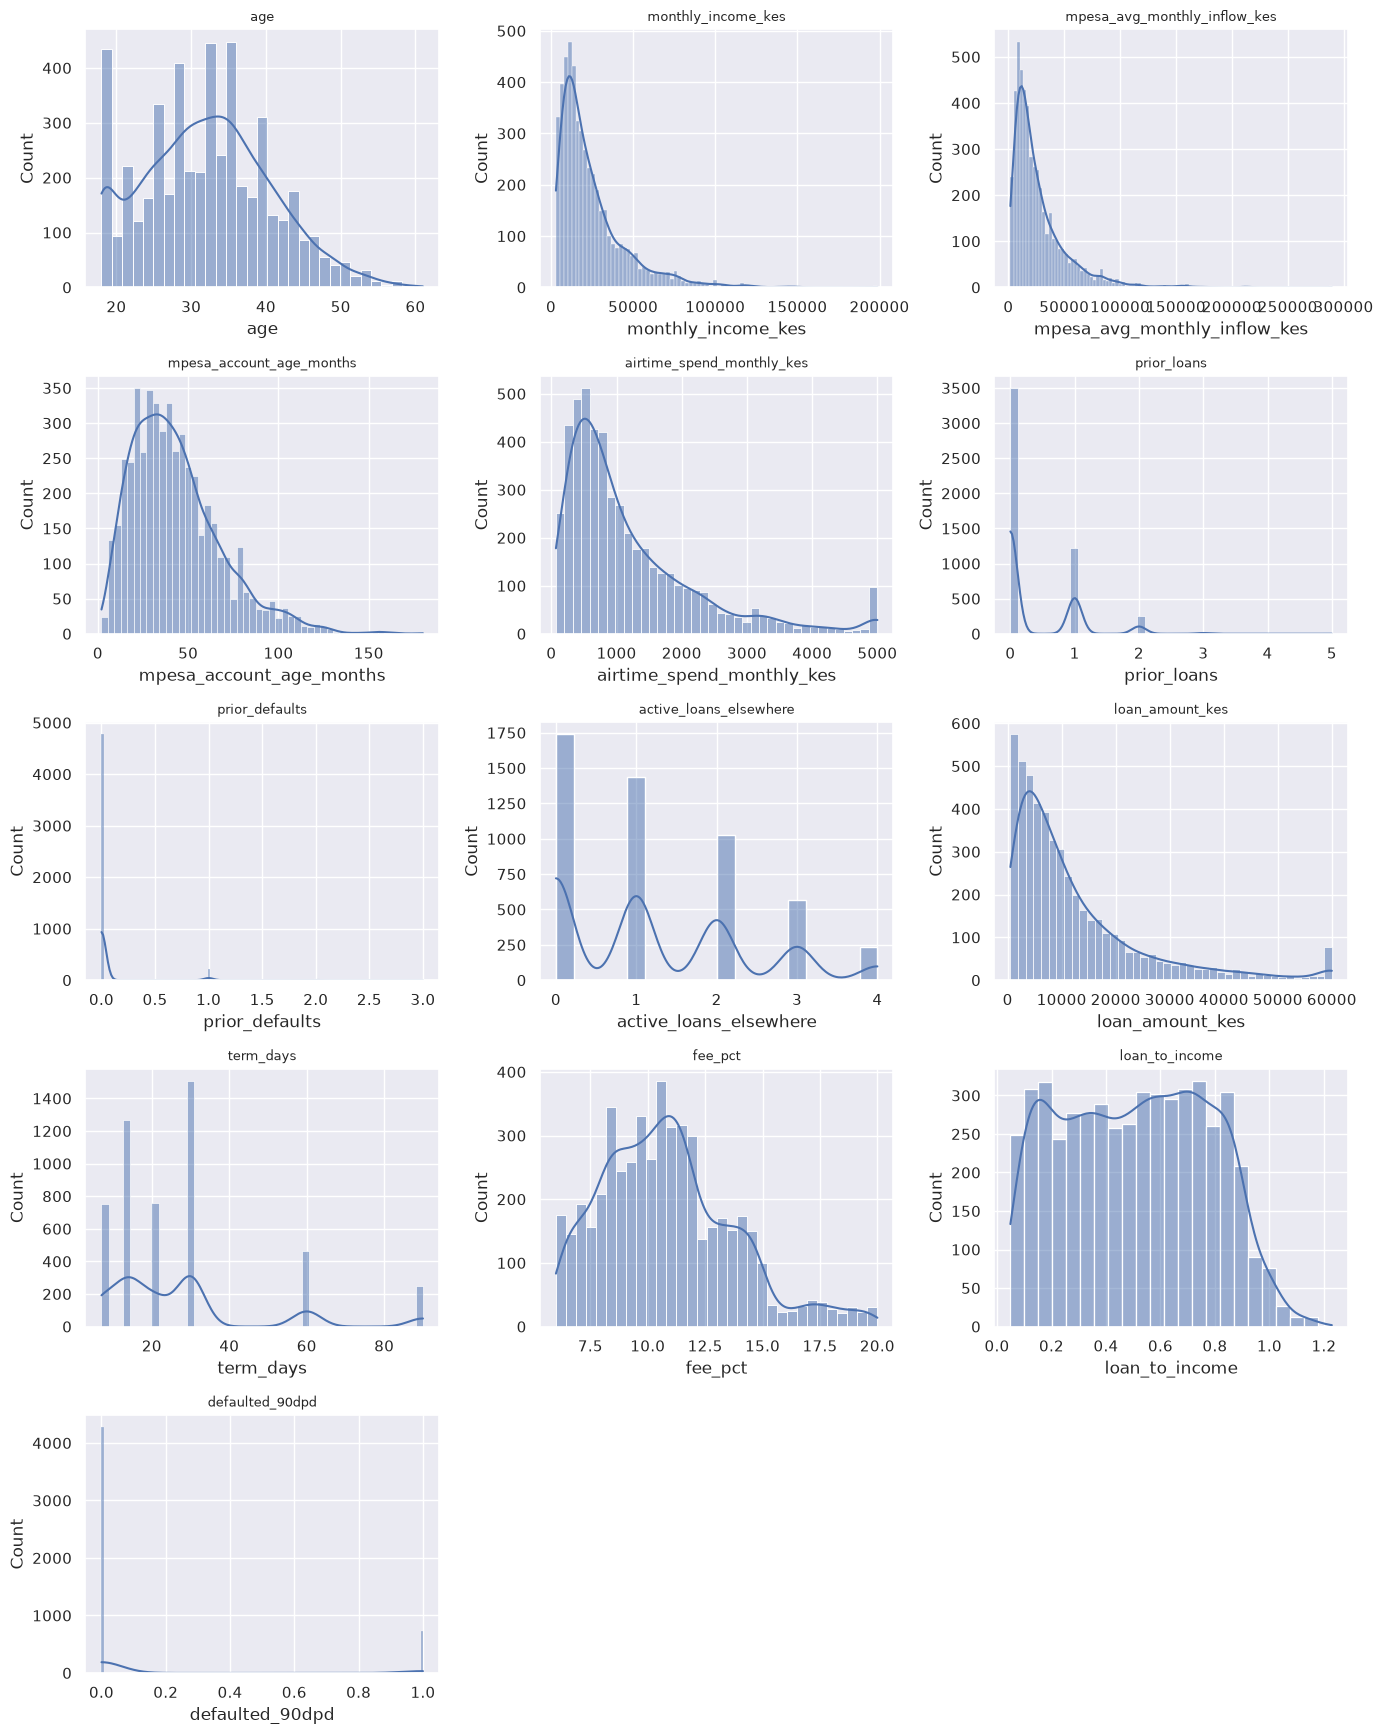

In [109]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flat

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col, fontsize=9)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [110]:
df = df.copy()


In [111]:
data = df.copy()
data["external_loans_per_account_month"] = data["active_loans_elsewhere"] / data["mpesa_account_age_months"].clip(lower=1)
data["external_loan_burden"] = data["active_loans_elsewhere"] * data["loan_to_income"]
groups = data["borrower_id"]
y = data["defaulted_90dpd"]
categorical_columns = ["county", "employment_type", "channel"]
X = pd.get_dummies(
    data.drop(columns=["loan_id", "borrower_id", "defaulted_90dpd"]),
    columns=categorical_columns,
    dtype=float,
)


In [112]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[tr], X.iloc[te]
y_train, y_test = y.iloc[tr], y.iloc[te]

gss_validation = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43)
tr_inner, va_inner = next(gss_validation.split(X_train, y_train, groups.iloc[tr]))
X_inner_train, X_validation = X_train.iloc[tr_inner], X_train.iloc[va_inner]
y_inner_train, y_validation = y_train.iloc[tr_inner], y_train.iloc[va_inner]

print(f"train={len(X_train)}  test={len(X_test)}  ")
print(f"default rate train={y_train.mean():.3f} test={y_test.mean():.3f}")
print(f"inner train={len(X_inner_train)}  validation={len(X_validation)}")


train=4000  test=1000  
default rate train=0.147 test=0.139
inner train=3012  validation=988


In [113]:
parameter_rows = []
for max_depth in [5, 8, 10]:
    for min_samples_leaf in [10, 20]:
        for min_samples_split in [2, 20, 50]:
            for ccp_alpha in [0.0, 0.0001]:
                candidate = DecisionTreeClassifier(
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    min_samples_split=min_samples_split,
                    ccp_alpha=ccp_alpha,
                    class_weight="balanced",
                    random_state=42,
                )
                candidate.fit(X_inner_train, y_inner_train)
                validation_proba = candidate.predict_proba(X_validation)[:, 1]
                parameter_rows.append({
                    "max_depth": max_depth,
                    "min_samples_leaf": min_samples_leaf,
                    "min_samples_split": min_samples_split,
                    "ccp_alpha": ccp_alpha,
                    "validation_roc_auc": roc_auc_score(y_validation, validation_proba),
                    "validation_pr_auc": average_precision_score(y_validation, validation_proba),
                })

parameter_results = pd.DataFrame(parameter_rows).sort_values(
    ["validation_pr_auc", "validation_roc_auc"], ascending=False
)
best_parameters = parameter_results.iloc[0][
    ["max_depth", "min_samples_leaf", "min_samples_split", "ccp_alpha"]
].to_dict()
best_parameters["max_depth"] = int(best_parameters["max_depth"])
best_parameters["min_samples_leaf"] = int(best_parameters["min_samples_leaf"])
best_parameters["min_samples_split"] = int(best_parameters["min_samples_split"])
print(parameter_results.head(10).to_string(index=False))
print("Selected parameters:", best_parameters)

tree = DecisionTreeClassifier(
    **best_parameters,
    class_weight="balanced",
    random_state=42,
)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)
y_proba = tree.predict_proba(X_test)[:, 1]

print("class_weight='balanced' prioritizes detection of costly missed defaults over false positives.")
print("Accuracy:", tree.score(X_test, y_test))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC:", average_precision_score(y_test, y_proba))
print("PR-AUC baseline:", y_test.mean())
print("PR-AUC lift:", average_precision_score(y_test, y_proba) / y_test.mean())
print(classification_report(y_test, y_pred, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))


 max_depth  min_samples_leaf  min_samples_split  ccp_alpha  validation_roc_auc  validation_pr_auc
         5                10                 50     0.0000            0.698431           0.273594
         5                10                 50     0.0001            0.698431           0.273594
         5                20                  2     0.0000            0.694088           0.270889
         5                20                  2     0.0001            0.694088           0.270889
         5                20                 20     0.0000            0.694088           0.270889
         5                20                 20     0.0001            0.694088           0.270889
         5                20                 50     0.0000            0.692839           0.269413
         5                20                 50     0.0001            0.692839           0.269413
         5                10                  2     0.0000            0.688214           0.267603
         5          

True grouped CV ROC-AUC: 0.703 ± 0.025
True grouped CV PR-AUC: 0.293 ± 0.034
Grouped CV PR-AUC baseline: 0.145
Grouped CV PR-AUC lift: 2.018x
external_loan_burden                0.483268
employment_type_Salaried            0.107048
external_loans_per_account_month    0.090569
loan_to_income                      0.077959
fee_pct                             0.046997
airtime_spend_monthly_kes           0.039451
active_loans_elsewhere              0.038108
mpesa_account_age_months            0.032756
loan_amount_kes                     0.025193
employment_type_Self-employed       0.019944
prior_defaults                      0.019407
channel_Agent-assisted              0.014135
age                                 0.005164
term_days                           0.000000
prior_loans                         0.000000
|--- external_loan_burden <= 0.59
|   |--- employment_type_Salaried <= 0.50
|   |   |--- active_loans_elsewhere <= 2.50
|   |   |   |--- loan_to_income <= 0.47
|   |   |   |   |--- tr

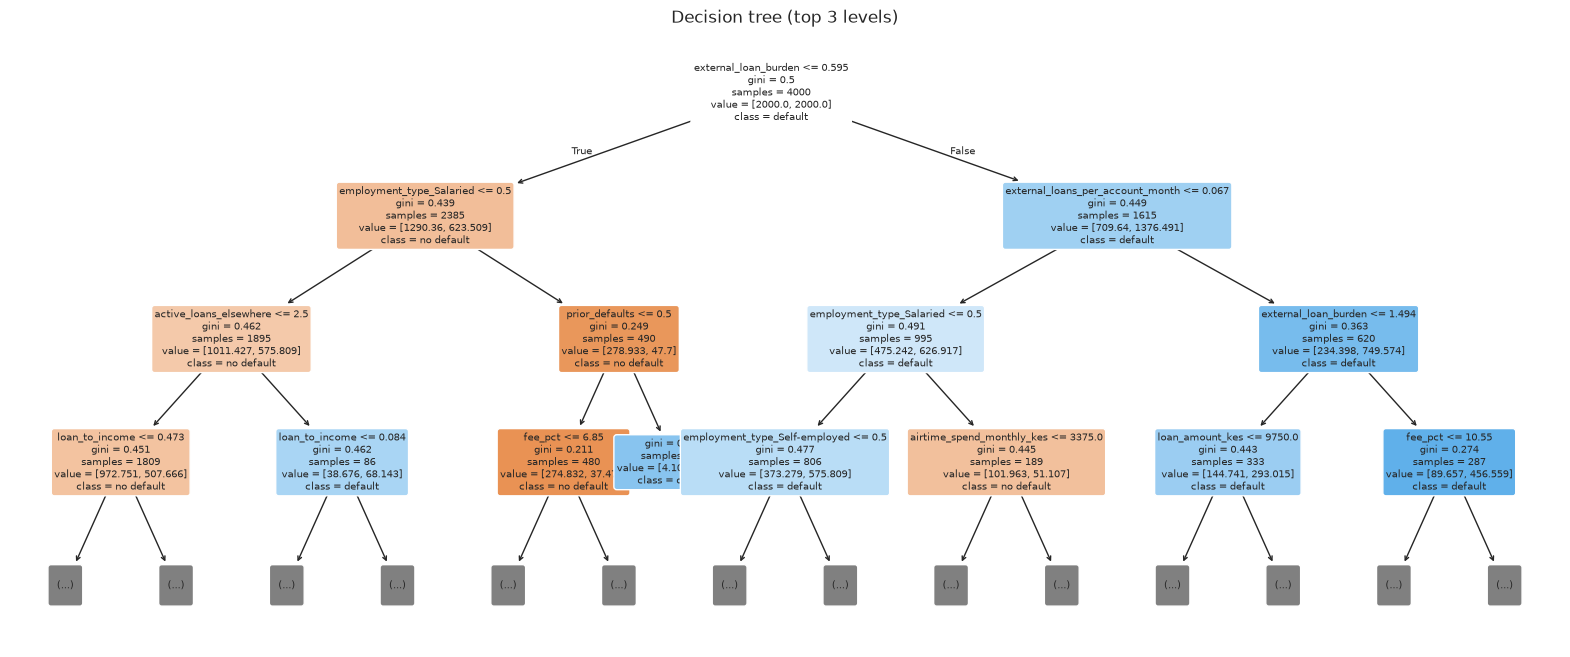

In [114]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
roc_scores = cross_val_score(tree, X, y, cv=cv, groups=groups, scoring="roc_auc")
pr_scores = cross_val_score(tree, X, y, cv=cv, groups=groups, scoring="average_precision")
print(f"True grouped CV ROC-AUC: {roc_scores.mean():.3f} ± {roc_scores.std():.3f}")
print(f"True grouped CV PR-AUC: {pr_scores.mean():.3f} ± {pr_scores.std():.3f}")
print(f"Grouped CV PR-AUC baseline: {y.mean():.3f}")
print(f"Grouped CV PR-AUC lift: {pr_scores.mean() / y.mean():.3f}x")

feature_importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(feature_importance.head(15).to_string())
print(export_text(tree, feature_names=list(X.columns), max_depth=3))
plt.figure(figsize=(20, 8))
plot_tree(tree, feature_names=X.columns, class_names=["no default", "default"], filled=True, rounded=True, fontsize=7, max_depth=3)
plt.title("Decision tree (top 3 levels)")
plt.show()


In [115]:
X_no_ratio = X.drop(columns=["loan_to_income"])
X_ratio_only = X.drop(columns=["loan_amount_kes", "monthly_income_kes"])
X_without_derived = X.drop(columns=["external_loans_per_account_month", "external_loan_burden"])
X_without_external_count = X.drop(columns=["active_loans_elsewhere", "external_loans_per_account_month", "external_loan_burden"])

feature_sets = {
    "raw_plus_ratio": X,
    "raw_without_ratio": X_no_ratio,
    "ratio_without_raws": X_ratio_only,
    "without_derived_features": X_without_derived,
    "without_external_loan_features": X_without_external_count,
}
comparison_rows = []
for name, X_variant in feature_sets.items():
    variant_tree = DecisionTreeClassifier(
        **best_parameters,
        class_weight="balanced",
        random_state=42,
    )
    variant_roc = cross_val_score(variant_tree, X_variant, y, cv=cv, groups=groups, scoring="roc_auc")
    variant_pr = cross_val_score(variant_tree, X_variant, y, cv=cv, groups=groups, scoring="average_precision")
    comparison_rows.append({
        "feature_set": name,
        "grouped_roc_auc": variant_roc.mean(),
        "grouped_pr_auc": variant_pr.mean(),
        "grouped_pr_auc_lift": variant_pr.mean() / y.mean(),
    })

comparison = pd.DataFrame(comparison_rows).sort_values("grouped_pr_auc", ascending=False)
print(comparison.to_string(index=False, formatters={
    "grouped_roc_auc": "{:.3f}".format,
    "grouped_pr_auc": "{:.3f}".format,
    "grouped_pr_auc_lift": "{:.2f}x".format,
}))


                   feature_set grouped_roc_auc grouped_pr_auc grouped_pr_auc_lift
                raw_plus_ratio           0.703          0.293               2.02x
            ratio_without_raws           0.707          0.292               2.01x
             raw_without_ratio           0.696          0.292               2.01x
      without_derived_features           0.682          0.266               1.83x
without_external_loan_features           0.611          0.205               1.41x


In [116]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
target_recall = 0.60
valid_indices = np.flatnonzero(recall[:-1] >= target_recall)
if len(valid_indices) == 0:
    raise ValueError(f"No threshold reaches recall >= {target_recall:.2f}")
threshold_index = valid_indices[-1]
tuned_threshold = thresholds[threshold_index]
y_pred_tuned = (y_proba >= tuned_threshold).astype(int)
print(f"threshold={tuned_threshold:.2f} precision={precision[threshold_index]:.2f} recall={recall[threshold_index]:.2f}")
print("Confusion matrix at tuned threshold:\n", confusion_matrix(y_test, y_pred_tuned))


threshold=0.55 precision=0.25 recall=0.62
Confusion matrix at tuned threshold:
 [[602 259]
 [ 53  86]]
